# Proyecto Final — SeñaBusca: diccionario inverso de ASL con cámara

**CC3092 · Deep Learning y Sistemas Inteligentes** — Universidad del Valle de Guatemala
**Esteban Cárcamo (23016) · Nicolás Concuá (23197)** — noviembre de 2026

Enlace al repositorio: https://github.com/nicoCT04/ProyectoFinal-DL

Este notebook documenta el flujo completo: datos → preprocesamiento → modelos (3 versiones +
baseline clásico) → modelo de valor → explicabilidad. **No es el producto final**: el producto es
la app web en `app/` (FastAPI + MediaPipe en el navegador). El entrenamiento pesado está en
`scripts/` para poder reproducirlo por terminal; aquí se cargan sus resultados (con la opción de
re-entrenar poniendo `ENTRENAR = True`).

In [1]:
import json, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

# Rutas robustas: funciona desde la raíz del proyecto o desde notebook/
ROOT = Path.cwd() if (Path.cwd() / "asl").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from asl.features import N_POSE, N_HAND, N_PTS, T_FIJO, preparar, normalizar, recortar_actividad
from asl.data import cargar_grupo, aumentar, reflejar, vocabulario
from asl.valor import SUPUESTOS_BASE, valor, mejor_umbral, costo_manual, supuestos_dict
SEED = 23197
ENTRENAR = False          # True = re-ejecuta scripts/03_entrenar.py (≈ 1–2 h en M4 Pro)
FIG, TAB = ROOT / "reports" / "figuras", ROOT / "reports" / "tablas"
pd.set_option("display.max_colwidth", 80)

## 1. Contexto y problema

Un estudiante de ASL ve una seña (en clase, en un video, en una conversación) y no sabe qué
significa. Los diccionarios están organizados **por palabra**: sirven para ir de *palabra → seña*,
no de *seña → palabra*. Hoy la alternativa es buscar por rasgos (forma de la mano, ubicación,
movimiento) en sitios especializados o preguntarle a alguien; es lento y muchas veces no se
encuentra. SeñaBusca invierte la búsqueda: el usuario hace la seña frente a la cámara y recibe las
3 coincidencias más probables.

**¿Por qué deep learning?** La misma seña varía entre personas (velocidad, amplitud, mano
dominante), cámaras e iluminación. Las reglas no capturan esa variación y un modelo clásico sobre
estadísticos pierde el orden temporal. Lo comprobamos abajo con un baseline sin deep learning.

## 2. Datos y análisis exploratorio

In [2]:
voc = vocabulario()
sub = pd.read_csv(ROOT / "data" / "subconjunto.csv")
obj = sub[sub.grupo == "objetivo"]
print("Señas objetivo:", len(voc["objetivo"]), "| señas de preentrenamiento:", len(voc["preentreno"]))
display(sub.groupby(["grupo", "split"]).agg(videos=("Video file", "size"),
        participantes=("Participant ID", "nunique"), senas=("Gloss", "nunique")))

Señas objetivo: 50 | señas de preentrenamiento: 450


videos  participantes  senas
grupo      split                              
objetivo   test      616             11     50
           train     732             29     50
           val       190              5     50
preentreno test     5451             11    450
           train    6615             35    450
           val      1701              5    450

train∩val: set() | train∩test: set() | val∩test: set()


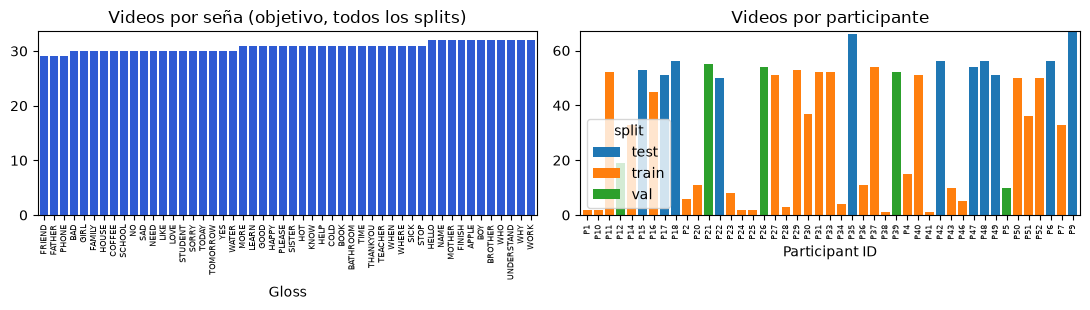

In [3]:
# ¿La separación es por persona? Ningún participante aparece en dos splits.
parts = obj.groupby("split")["Participant ID"].apply(set)
print("train∩val:", parts["train"] & parts["val"], "| train∩test:", parts["train"] & parts["test"],
      "| val∩test:", parts["val"] & parts["test"])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
obj.groupby("Gloss").size().sort_values().plot.bar(ax=axs[0], color="#2f5bd3", width=0.8)
axs[0].set_title("Videos por seña (objetivo, todos los splits)"); axs[0].tick_params(axis="x", labelsize=6)
obj.groupby(["split", "Participant ID"]).size().unstack(0).plot.bar(ax=axs[1], stacked=True, width=0.8)
axs[1].set_title("Videos por participante"); axs[1].tick_params(axis="x", labelsize=6)
plt.tight_layout(); plt.savefig(FIG / "eda_distribuciones.png"); plt.show()

,cuadros,frac_manos,frac_pose,frac_izq,frac_der
count,1538.000,1538.000,1538.000,1538.000,1538.000
mean,77.574,0.447,1.000,0.262,0.344
std,37.308,0.135,0.007,0.224,0.171
min,17.000,0.000,0.821,0.000,0.000
25%,54.000,0.361,1.000,0.014,0.279
50%,71.000,0.434,1.000,0.293,0.372
75%,90.000,0.514,1.000,0.435,0.451
max,664.000,1.000,1.000,1.000,1.000


Videos sin ninguna mano detectada: 1


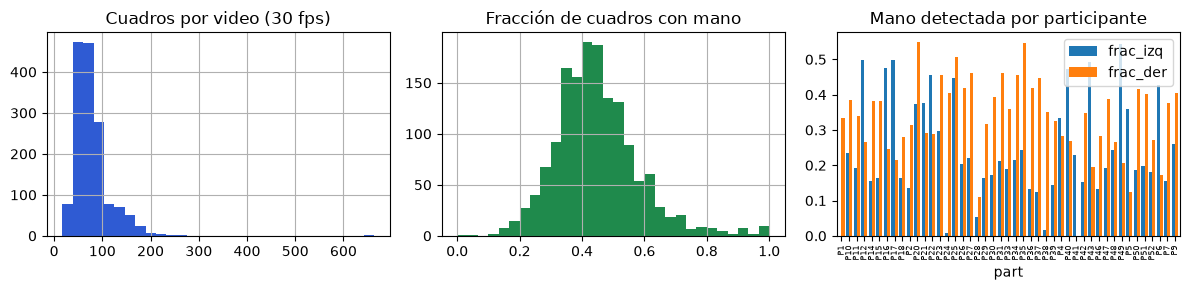

In [4]:
# Calidad de la detección: largo de los videos y fracción de cuadros con manos detectadas.
filas = []
for _, r in obj.iterrows():
    a = np.load(ROOT / "data" / "landmarks" / (r["Video file"][:-4] + ".npy")).astype(np.float32)
    manos = ~np.isnan(a[:, N_POSE:, 0]).all(1)
    filas.append(dict(split=r.split, gloss=r.Gloss, part=r["Participant ID"], cuadros=len(a),
                      frac_manos=manos.mean(), frac_pose=(~np.isnan(a[:, 0, 0])).mean(),
                      frac_izq=(~np.isnan(a[:, N_POSE:N_POSE+N_HAND, 0]).all(1)).mean(),
                      frac_der=(~np.isnan(a[:, N_POSE+N_HAND:, 0]).all(1)).mean()))
q = pd.DataFrame(filas)
display(q.describe().round(3))
print("Videos sin ninguna mano detectada:", (q.frac_manos == 0).sum())
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
q.cuadros.hist(ax=axs[0], bins=30, color="#2f5bd3"); axs[0].set_title("Cuadros por video (30 fps)")
q.frac_manos.hist(ax=axs[1], bins=30, color="#1f8a4c"); axs[1].set_title("Fracción de cuadros con mano")
q.groupby("part")[["frac_izq", "frac_der"]].mean().plot.bar(ax=axs[2], width=0.8)
axs[2].set_title("Mano detectada por participante"); axs[2].tick_params(axis="x", labelsize=6)
plt.tight_layout(); plt.savefig(FIG / "eda_calidad_deteccion.png"); plt.show()

**Lectura del EDA.** Las clases están prácticamente balanceadas (~30 videos por seña), por lo que
la accuracy y el F1 macro cuentan casi lo mismo. El desbalance real está en las **personas**: cada
participante grabó un número distinto de videos y algunos usan la mano izquierda como
dominante; por eso el split oficial (por participante) es el correcto para imitar el uso real: el
usuario de la app nunca está en el entrenamiento.

### 2.1 Preprocesamiento

1. **MediaPipe** (manos + pose) en modo VIDEO (con seguimiento entre cuadros, igual que en el
   navegador) → 53 puntos (x, y, z) por cuadro: 11 de la parte superior del cuerpo y 21 por mano.
   El video nunca sale del navegador en la app: solo viajan estos números. (Una primera versión
   usó modo IMAGE y eso creó un desajuste entre entrenamiento y producción; ver sección 4.1.)
2. **Recorte de reposo**: se quitan los cuadros iniciales/finales sin manos.
3. **Normalización**: centro en el punto medio de los hombros y escala por el ancho de hombros →
   invariancia a la posición y a la distancia a la cámara.
4. **Remuestreo** a 64 cuadros e indicadores de presencia de cada mano → tensor (64, 161).

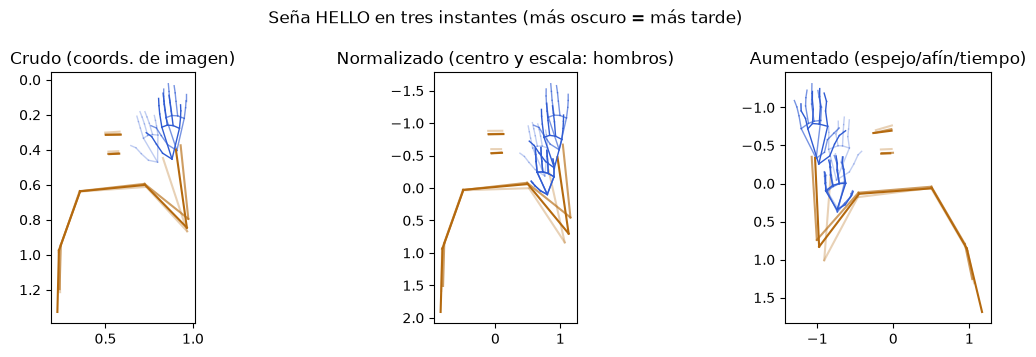

In [5]:
r = obj[obj.Gloss == "HELLO"].iloc[0]
cr = np.load(ROOT / "data" / "landmarks" / (r["Video file"][:-4] + ".npy")).astype(np.float32)
x = preparar(cr)
rng = np.random.default_rng(SEED)
MANO = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),(9,13),(13,14),
        (14,15),(15,16),(13,17),(17,18),(18,19),(19,20),(0,17)]
POSE = [(5,6),(5,7),(7,9),(6,8),(8,10),(1,2),(3,4)]
def esqueleto(ax, pts, titulo):
    # Tres instantes de la seña: inicio (claro), mitad y final (oscuro).
    validos = [t for t in range(len(pts)) if not np.isnan(pts[t, N_POSE:, 0]).all()]
    for k, t in enumerate([validos[len(validos)//5], validos[len(validos)//2], validos[-len(validos)//5]]):
        p = pts[t]; a = 0.3 + 0.35 * k
        for i, j in POSE:
            ax.plot(p[[i, j], 0], p[[i, j], 1], color="#b4690e", alpha=a, lw=1.5)
        for off in (N_POSE, N_POSE + N_HAND):
            h = p[off:off+N_HAND, :2]
            if np.isnan(h).all() or np.abs(h).max() < 1e-6 or np.abs(h).std() < 1e-3:
                continue   # mano no detectada en ese cuadro
            for i, j in MANO:
                ax.plot(p[[off+i, off+j], 0], p[[off+i, off+j], 1], color="#2f5bd3", alpha=a, lw=1)
    ax.invert_yaxis(); ax.set_aspect("equal"); ax.set_title(titulo)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
esqueleto(axs[0], cr, "Crudo (coords. de imagen)")
esqueleto(axs[1], x[:, :N_PTS*3].reshape(64, N_PTS, 3), "Normalizado (centro y escala: hombros)")
esqueleto(axs[2], aumentar(x, rng)[:, :N_PTS*3].reshape(64, N_PTS, 3), "Aumentado (espejo/afín/tiempo)")
plt.suptitle("Seña HELLO en tres instantes (más oscuro = más tarde)")
plt.tight_layout(); plt.savefig(FIG / "preprocesamiento.png"); plt.show()

## 3. Modelos e iteraciones

| Versión | Idea | Por qué |
|---|---|---|
| Baseline clásico | Regresión logística / k-NN sobre estadísticos | ¿Hace falta deep learning? |
| **v0** | LSTM bidireccional desde cero (Lab 3) | Modelo secuencial base |
| **v1** | Transformer encoder desde cero (HT 2) | La atención relaciona inicio y fin de la seña |
| **v2** | Transformer **preentrenado en 450 señas distintas** + fine-tuning (Lab 6) | Transfer learning: aprender "cómo se mueven las manos" con más datos |

El preentrenamiento usa solo participantes de **entrenamiento** y señas que **no** están entre las
50 objetivo, así que no hay fuga de información hacia prueba. Todas las iteraciones se corren con
3 semillas; el mejor epoch se elige con validación y prueba se evalúa una sola vez.

In [6]:
if ENTRENAR:
    import subprocess
    subprocess.run([sys.executable, "scripts/03_entrenar.py", "it0_lstm_base", "it1_lstm_aug", "it2_tf_aug",
                    "it3_tf_aug_small", "pre_tf", "pre_lstm", "it4_tl_tf_congelado", "it5_tl_tf_finetune",
                    "it6_tl_lstm_finetune", "it7_tl_tf_webcam"], cwd=ROOT, check=True)
    subprocess.run([sys.executable, "scripts/05_modelo_valor.py"], cwd=ROOT, check=True)
tabla = pd.read_csv(TAB / "tabla_iteraciones.csv")
display(tabla)

,Iteración,Cambio,Semillas,Parámetros,Top-1 train,Top-1 val,Top-1 test,Top-3 test,F1 macro test,Umbral (val),Valor neto USD/mes (test),Búsquedas resueltas,"Entrenamiento (min, M4 Pro)",Latencia CPU (ms)
0,clasico_logreg,Regresión logística sobre estadísticos (sin DL),1,NaN,1.000,0.695,0.617,0.799,0.618,0.76,"5,607",0.894,0.0,0.1
1,clasico_knn,k-NN sobre estadísticos (sin DL),1,NaN,1.000,0.521,0.451,0.687,0.444,0.82,"4,504",0.859,0.0,1.5
2,it0_lstm_base,"LSTM bidireccional, sin aumentos",3,1531442.0,0.999 ± 0.001,0.798 ± 0.006,0.689 ± 0.030,0.870 ± 0.013,0.682 ± 0.033,0.99 ± 0.01,"6,223 ± 52",0.920 ± 0.003,0.6,2.1
3,it1_lstm_aug,"+ aumentos (espejo, afín, tiempo) y label smoothing",3,1531442.0,1.000,0.863 ± 0.021,0.813 ± 0.003,0.932 ± 0.008,0.810 ± 0.004,0.65 ± 0.07,"6,365 ± 63",0.918 ± 0.001,2.0,2.0
4,it2_tf_aug,"Transformer encoder (4 capas, d=192) + aumentos",3,1833650.0,0.999 ± 0.002,0.935 ± 0.008,0.895 ± 0.012,0.966 ± 0.007,0.894 ± 0.013,0.84 ± 0.03,"6,649 ± 27",0.931 ± 0.002,3.6,1.7
5,it3_tf_aug_small,"Transformer más pequeño (3 capas, d=128, dropout 0.3)",3,630962.0,0.996 ± 0.002,0.921 ± 0.005,0.880 ± 0.005,0.964 ± 0.004,0.878 ± 0.004,0.91 ± 0.02,"6,695 ± 53",0.935 ± 0.001,2.1,0.8
6,it4_tl_tf_congelado,"TL: Transformer preentrenado en 450 señas, backbone congelado",3,1833650.0,0.992 ± 0.007,0.928 ± 0.013,0.886 ± 0.005,0.968 ± 0.006,0.885 ± 0.004,0.68 ± 0.03,"6,757 ± 51",0.935 ± 0.001,0.3 + 4.3 preentreno,1.8
7,it5_tl_tf_finetune,TL: Transformer preentrenado + fine-tuning completo (lr backbone 1e-4),3,1833650.0,0.998 ± 0.001,0.944 ± 0.003,0.899 ± 0.008,0.972 ± 0.001,0.897 ± 0.009,0.80 ± 0.03,"6,739 ± 21",0.935 ± 0.001,0.8 + 4.3 preentreno,1.8
8,it6_tl_lstm_finetune,TL: LSTM preentrenada en 450 señas + fine-tuning,3,1531442.0,0.999 ± 0.001,0.928 ± 0.013,0.873 ± 0.002,0.956 ± 0.008,0.870 ± 0.002,0.63 ± 0.05,"6,622 ± 51",0.929 ± 0.001,1.0 + 4.5 preentreno,2.1
9,it7_tl_tf_webcam,"it5 + aumentos de cámara en vivo (seña cortada, encuadre, mano perdida)",3,1833650.0,0.987 ± 0.015,0.946 ± 0.006,0.900 ± 0.005,0.977 ± 0.004,0.899 ± 0.007,0.76 ± 0.07,"6,787 ± 21",0.935 ± 0.002,0.8 + 4.3 preentreno,1.8


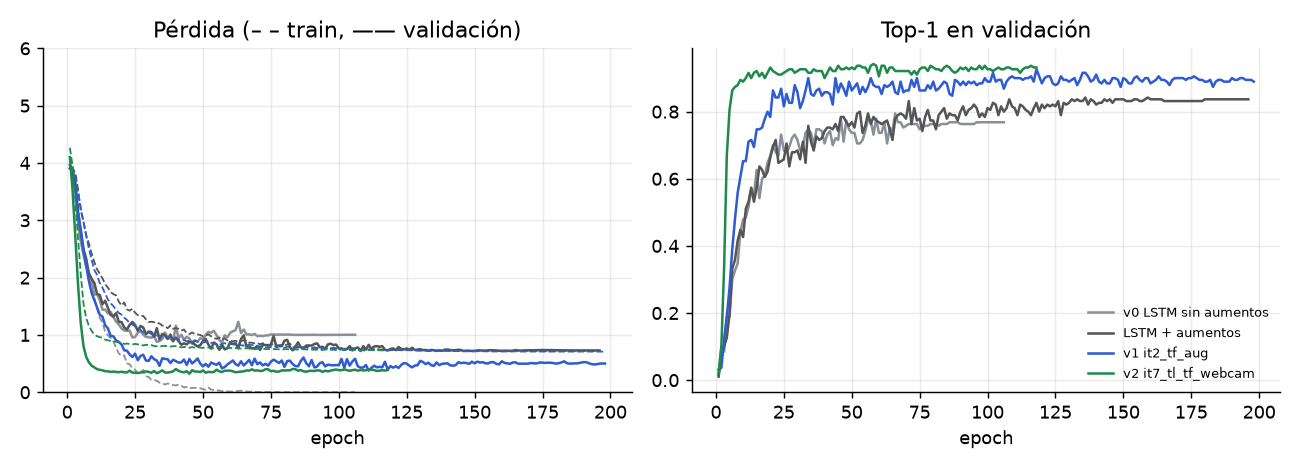

In [7]:
display(Image(FIG / 'curvas_entrenamiento.png'))

## 4. Modelo de valor

**Escenario.** Un programa de enseñanza de ASL con 500 estudiantes activos que hacen ~20
búsquedas de señas desconocidas al mes (10 000 búsquedas/mes). Valoramos el tiempo de un
estudiante en 12 USD/h.

**Función de valor (por búsqueda, en segundos equivalentes):**

* *Sin la app:* `C_manual = t_manual + (1 − p_manual) · c_no_resuelta`.
* *Con la app*, según la confianza `c` (masa de probabilidad del top-3) y el umbral `τ`:
  * `c ≥ τ` → **modo seguro** (3 opciones): `t_grabar + t_rev3` si la seña correcta está en el
    top-3; si no, con prob. `p_engano` el usuario acepta una opción equivocada (`c_error`) y si no,
    revisa 10 opciones (`t_rev10`) y, si tampoco está, busca a mano.
  * `c < τ` → **modo "no estoy seguro"** (10 opciones con aviso): `t_grabar + t_rev10`; el aviso
    baja el engaño a `p_engano_aviso`.
* `Valor neto/mes = (C_manual − E[C_app]) · búsquedas/mes · valor_hora / 3600 − costo_operación`.

El umbral **traduce la confianza del modelo en experiencia de usuario**: mostrar 3 opciones es más
rápido, pero si el modelo se equivoca con seguridad el usuario puede aprender una seña mal.

In [8]:
display(pd.DataFrame([supuestos_dict()]).T.rename(columns={0: "valor"}))
print(f"Costo esperado de una búsqueda manual: {costo_manual(SUPUESTOS_BASE):.0f} s")

,valor
t_grabar,8.00000
t_rev3,15.00000
t_rev10,45.00000
t_manual,180.00000
p_manual,0.65000
p_engano,0.30000
p_engano_aviso,0.05000
c_error,600.00000
c_no_resuelta,300.00000
p_vocab,0.85000


Costo esperado de una búsqueda manual: 285 s


In [9]:
tv = pd.read_csv(TAB / "tabla_versiones.csv")
display(tv)
resumen = json.loads((TAB / "resumen_valor.json").read_text())
print("IC 95 % de las diferencias de valor (USD/mes):", resumen["ic95_diferencias_valor"])
print("Escenario pesimista:", json.dumps(resumen["escenarios"], indent=1))

,Versión,Iteración,Semilla,Umbral,Top-1 test,IC95 top-1,Top-3 test,IC95 top-3,Seg/búsqueda app,Seg/búsqueda manual,Resueltas,Engaños,Modo seguro,OOV detectadas,Horas ahorradas/mes,Valor neto USD/mes,IC95 valor,Costo operación USD/mes,Latencia CPU ms,Entrenamiento min
0,v0,it0_lstm_base,2,0.98,0.656,"[0.576, 0.733]",0.862,"[0.816, 0.909]",99.2,285.0,0.916,0.029,0.618,0.649,516.2,6169.0,"[5,891, 6,390]",25.2,2.1,0.6
1,v1,it2_tf_aug,0,0.83,0.883,"[0.862, 0.907]",0.969,"[0.954, 0.983]",85.1,285.0,0.929,0.020,0.752,0.754,555.2,6637.0,"[6,541, 6,739]",25.2,1.7,3.6
2,v2,it7_tl_tf_webcam,1,0.83,0.906,"[0.878, 0.931]",0.981,"[0.971, 0.989]",80.4,285.0,0.937,0.014,0.731,0.866,568.4,6795.0,"[6,723, 6,860]",25.2,1.8,0.8


IC 95 % de las diferencias de valor (USD/mes): {'v1_menos_v0': [255.99807269022787, 724.9735498659448], 'v2_menos_v1': [71.19917173278398, 242.0083325527516], 'v2_menos_v0': [441.8634613004599, 851.9788366617989]}
Escenario pesimista: {
 "v0": {
  "base": 6168.984201129545,
  "pesimista": -14.048836580087226,
  "umbral_pesimista": 1.0
 },
 "v1": {
  "base": 6636.9609719680875,
  "pesimista": 207.6436366971862,
  "umbral_pesimista": 0.92
 },
 "v2": {
  "base": 6795.401332086094,
  "pesimista": 319.15476689312317,
  "umbral_pesimista": 0.91
 }
}


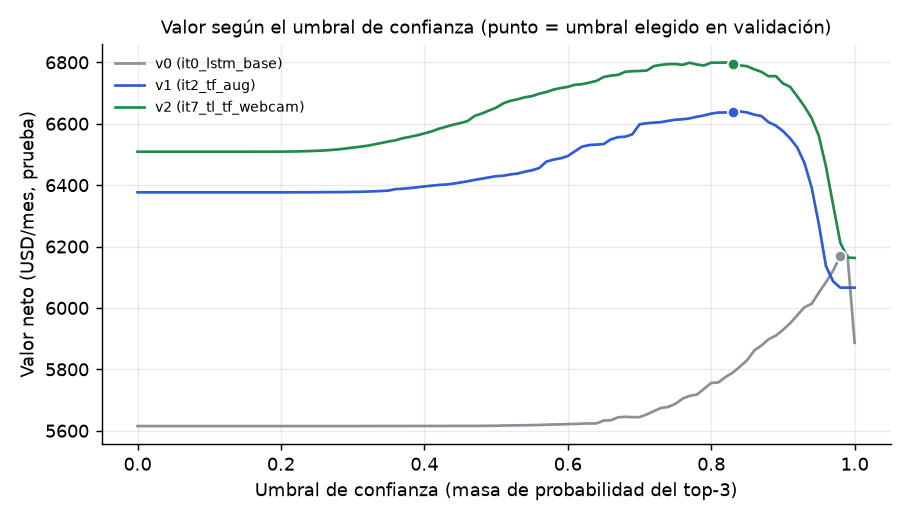

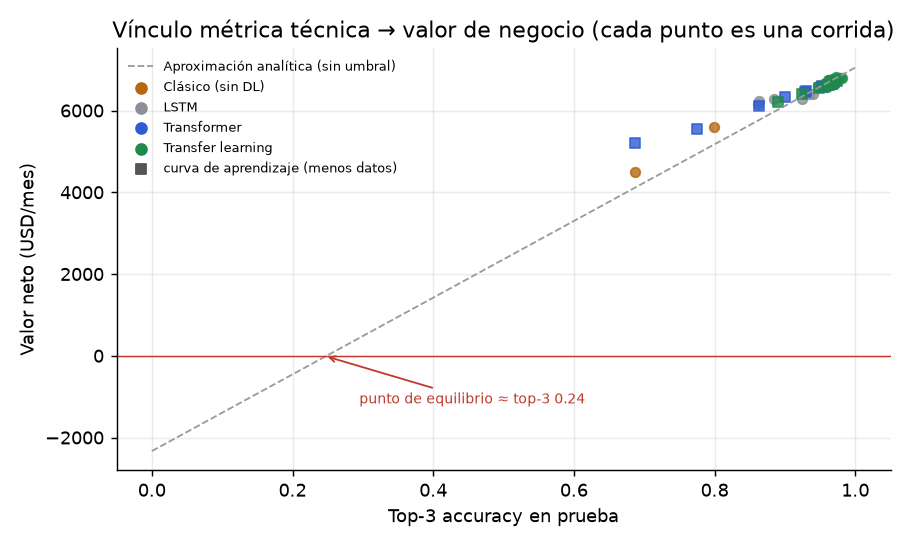

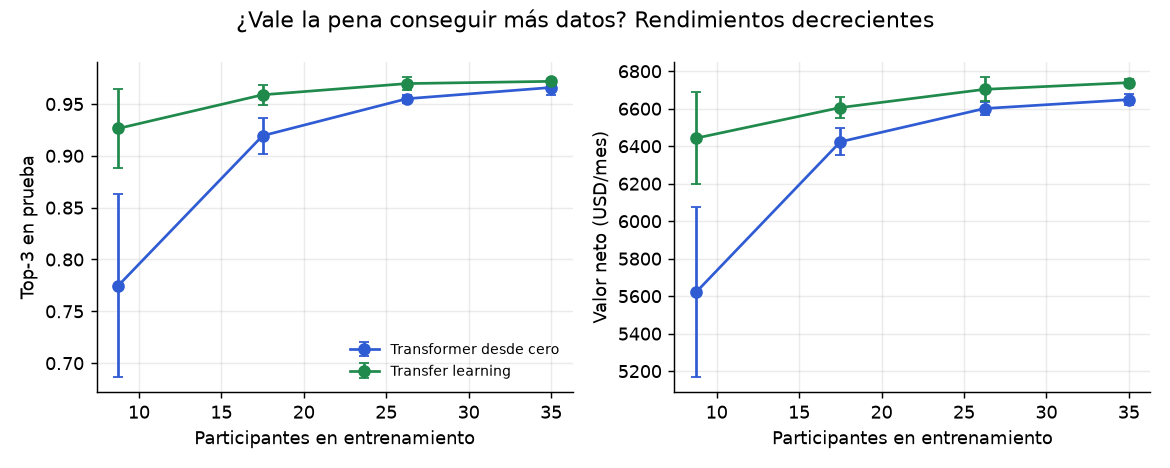

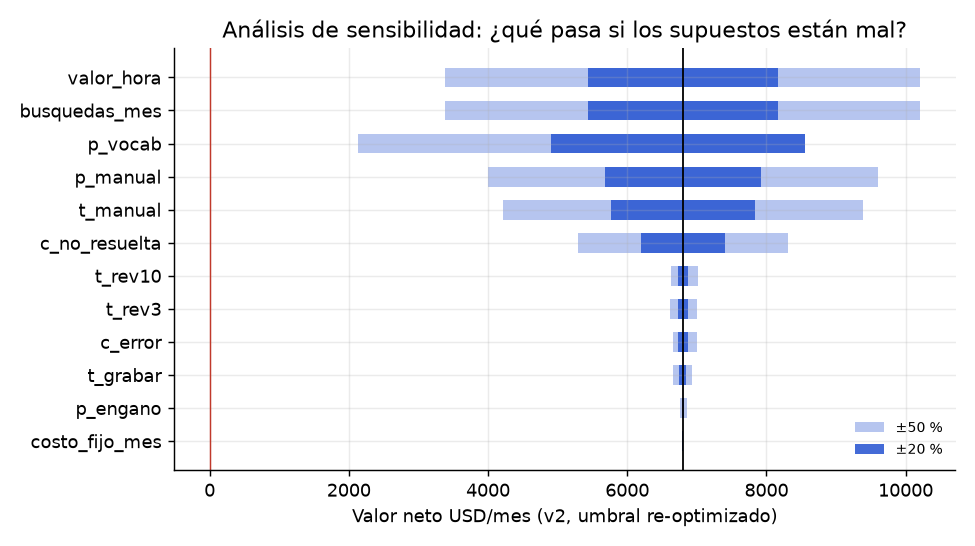

In [10]:
for f in ["valor_vs_umbral.png", "valor_vs_top3.png", "curva_aprendizaje.png", "sensibilidad_tornado.png"]:
    if (FIG / f).exists(): display(Image(FIG / f))

In [11]:
display(pd.read_csv(TAB / 'sensibilidad.csv').round(0))

,supuesto,valor_base,x0.5,delta_vs_v0_x0.5,x0.8,delta_vs_v0_x0.8,x1.2,delta_vs_v0_x1.2,x1.5,delta_vs_v0_x1.5,rango_50
0,costo_fijo_mes,25.0,6808.0,626.0,6800.0,626.0,6790.0,626.0,6783.0,626.0,25.0
1,p_engano,0.0,6856.0,571.0,6822.0,602.0,6781.0,662.0,6755.0,671.0,101.0
2,t_grabar,8.0,6929.0,626.0,6849.0,626.0,6742.0,626.0,6662.0,626.0,267.0
3,c_error,600.0,7005.0,510.0,6869.0,584.0,6735.0,654.0,6657.0,712.0,348.0
4,t_rev3,15.0,6996.0,673.0,6878.0,647.0,6722.0,615.0,6610.0,567.0,386.0
5,t_rev10,45.0,7018.0,382.0,6879.0,551.0,6728.0,689.0,6621.0,800.0,397.0
6,c_no_resuelta,300.0,5292.0,597.0,6194.0,615.0,7402.0,644.0,8307.0,664.0,3015.0
7,t_manual,180.0,4219.0,576.0,5765.0,606.0,7833.0,653.0,9385.0,689.0,5166.0
8,p_manual,1.0,9600.0,694.0,7919.0,655.0,5679.0,605.0,4004.0,572.0,5597.0
9,p_vocab,1.0,2137.0,352.0,4905.0,556.0,8548.0,742.0,8548.0,742.0,6411.0


### 4.1 Iteración de datos: modo IMAGE vs. modo VIDEO de MediaPipe

A: entrenado y evaluado con extracción IMAGE (lo que se creía). B: el mismo modelo evaluado con
extracción VIDEO, que es lo que produce la app en el navegador. C: re-entrenado con VIDEO.

In [12]:
if (TAB / "tabla_iteracion_datos.csv").exists():
    display(pd.read_csv(TAB / "tabla_iteracion_datos.csv"))
if (TAB / "prueba_app_e2e.json").exists():
    print(json.dumps(json.loads((TAB / "prueba_app_e2e.json").read_text()), indent=1, ensure_ascii=False))

,Iteración,A: entrena IMAGE / evalúa IMAGE (top-1 | top-3),B: entrena IMAGE / evalúa VIDEO = app (top-1 | top-3),C: entrena VIDEO / evalúa VIDEO (top-1 | top-3)
0,it0_lstm_base,0.679 | 0.869,0.643 | 0.830,0.689 | 0.870
1,it1_lstm_aug,0.768 | 0.920,0.722 | 0.888,0.813 | 0.932
2,it2_tf_aug,0.887 | 0.960,0.837 | 0.946,0.895 | 0.966
3,it3_tf_aug_small,0.880 | 0.962,0.820 | 0.940,0.880 | 0.964


{
 "descripcion": "60 videos de prueba (participantes no vistos, muestra con semilla 11) pasados por el flujo completo de la app en el navegador: MediaPipe Tasks JS modo VIDEO + segmentación automática + /api/predict. Videos cargados con el botón de subir video (mismo flujo que la cámara).",
 "v2_desplegado": {
  "n": 60,
  "top1": 57,
  "top3": 59,
  "top10": 60,
  "modo_seguro": 51,
  "modelo": "it5_tl_tf_finetune_s2 (umbral 0.78)",
  "fallos_top3": [
   "SISTER -> TIME/STOP/FRIEND"
  ]
 },
 "v0": {
  "n": 60,
  "top1": 44,
  "top3": 54,
  "top10": 58,
  "modo_seguro": 38,
  "modelo": "it0_lstm_base_s2 (umbral 0.98)"
 },
 "transformer_video": {
  "n": 60,
  "top1": 57,
  "top3": 59,
  "top10": 60,
  "modo_seguro_umbral_0.9": 39,
  "fallos_top3": [
   "MOTHER -> BAD/WATER/THANKYOU"
  ],
  "modelo": "it2_tf_aug_s2 (extracción VIDEO)"
 },
 "transformer_image": {
  "n": 60,
  "top1": 50,
  "top3": 56,
  "top10": 60,
  "modelo": "it2_tf_aug_s2 entrenado con extracción IMAGE"
 }
}


### 4.2 Robustez ante la cámara en vivo (it7) y prueba con cámara simulada

Fallas típicas de la cámara aplicadas a los puntos crudos de prueba (`scripts/14_robustez_webcam.py`):
it7 repite el fine-tuning de it5 con aumentos que las imitan. Después, los 616 videos de prueba pasan
por la app como una webcam en tiempo real (`scripts/13_prueba_camara_simulada.py`).

In [13]:
if (TAB / "robustez_webcam.csv").exists():
    display(pd.read_csv(TAB / "robustez_webcam.csv"))
if (TAB / "prueba_camara_simulada.json").exists():
    cs = json.loads((TAB / "prueba_camara_simulada.json").read_text())
    display(pd.DataFrame(cs["modelos"]).T[["archivo", "top1", "top3"]])
    print({k: cs[k] for k in ["videos", "grabaciones", "senas_sin_grabacion", "senas_partidas"]})

,perturbación,it5_tl_tf_finetune top1,it5_tl_tf_finetune top3,it7_tl_tf_webcam top1,it7_tl_tf_webcam top3
0,original,0.899,0.972,0.900,0.977
1,seña cortada: primer 60 %,0.810,0.927,0.820,0.950
2,seña cortada: último 60 %,0.810,0.912,0.825,0.933
3,seña cortada: primer 80 %,0.880,0.962,0.886,0.970
4,manos perdidas en 20 % de cuadros,0.898,0.969,0.897,0.975
5,manos perdidas en 40 % de cuadros,0.894,0.969,0.890,0.975
6,15 fps,0.896,0.965,0.894,0.973
7,hombros sin detectar,0.798,0.929,0.807,0.938
8,cámara 1.4× más cerca,0.841,0.942,0.859,0.960
9,15 cuadros de reposo extra al final,0.873,0.964,0.867,0.968


,archivo,top1,top3
v0,it0_lstm_base_s2,0.602273,0.814935
v1,it2_tf_aug_s0,0.814935,0.902597
v2,it7_tl_tf_webcam_s1,0.844156,0.930195


{'videos': 616, 'grabaciones': 601, 'senas_sin_grabacion': 24, 'senas_partidas': 9}


## 5. Explicabilidad, sesgos y robustez

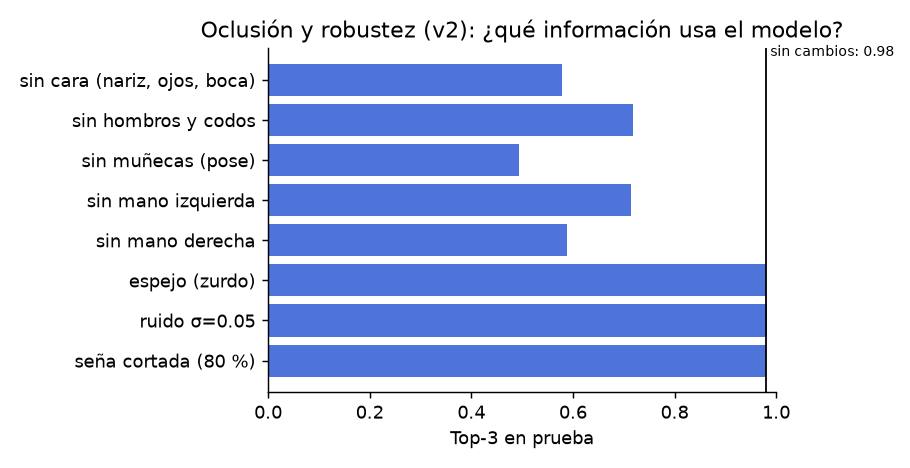

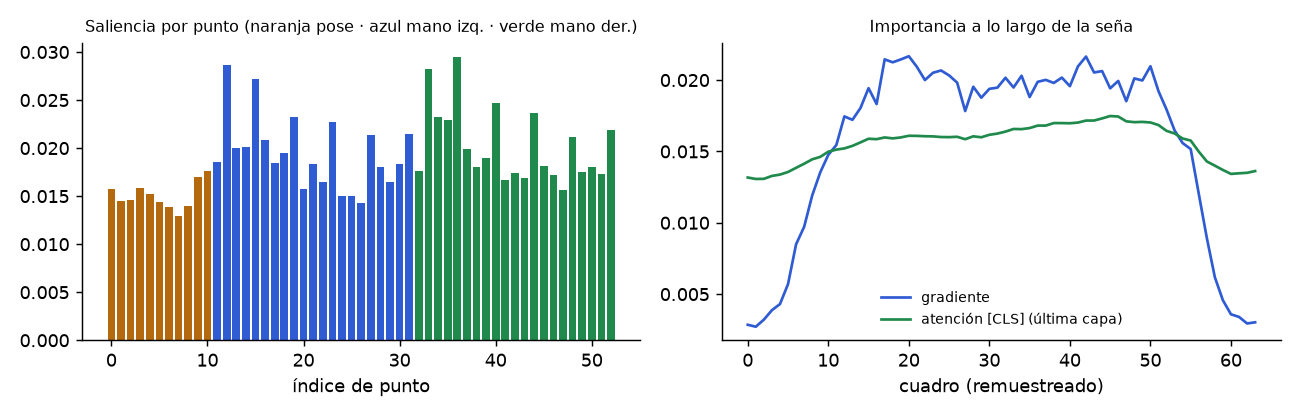

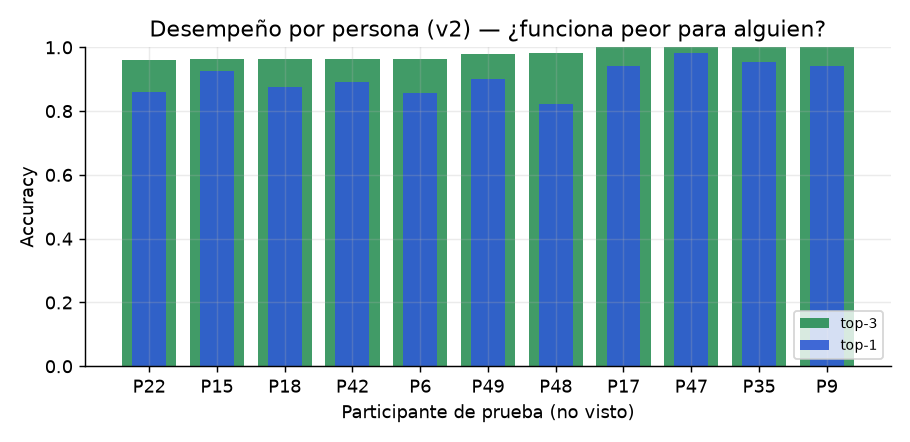

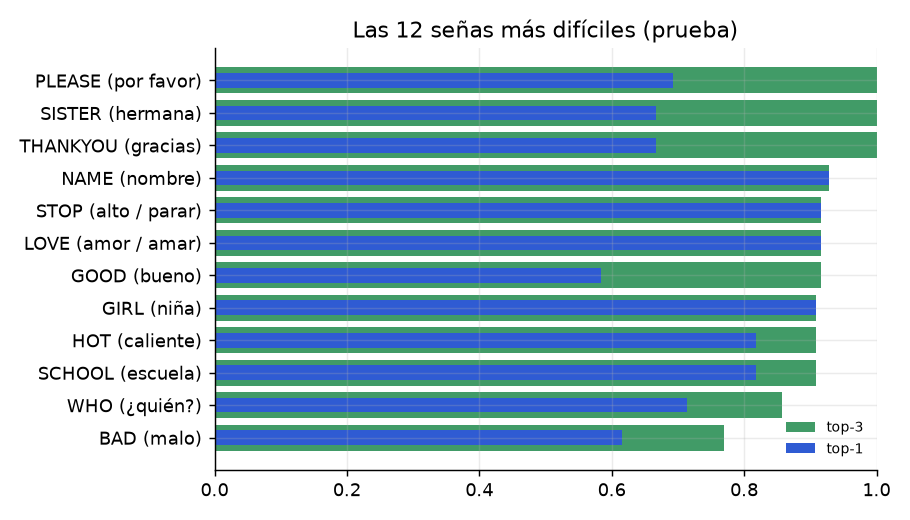

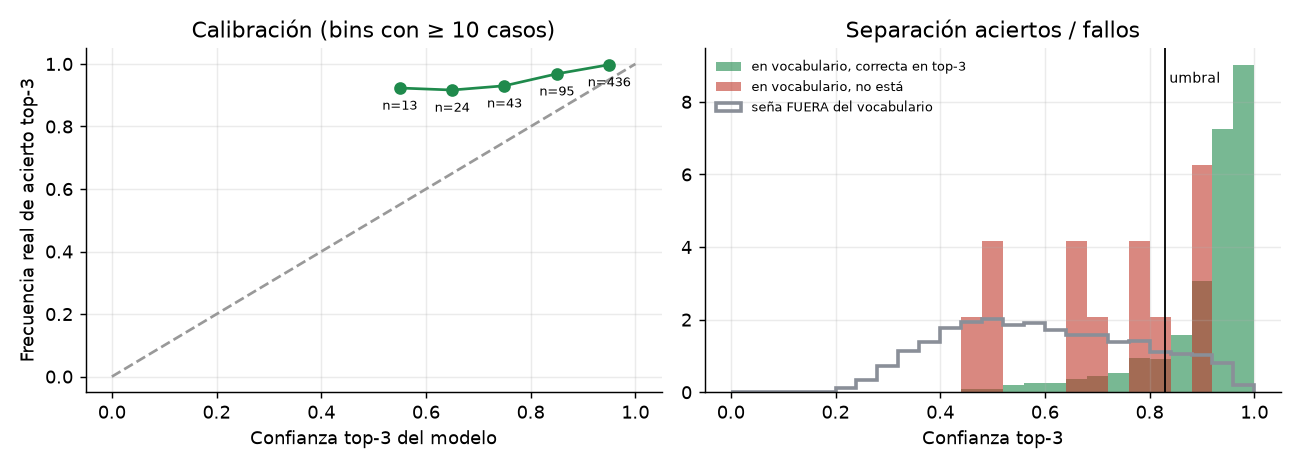

,Unnamed: 0,veces
0,PLEASE → HAPPY,4
1,GOOD → THANKYOU,4
2,THANKYOU → GOOD,4
3,BAD → GOOD,3
4,SISTER → BROTHER,3
5,HOT → BAD,2
6,BAD → HOT,2
7,MOTHER → WATER,1
8,NEED → YES,1
9,GIRL → TOMORROW,1


{
 "v0": {
  "base_top3": 0.862012987012987,
  "sin cara (nariz, ojos, boca)": 0.6412337662337663,
  "sin hombros y codos": 0.8214285714285714,
  "sin muñecas (pose)": 0.538961038961039,
  "sin mano izquierda": 0.5925324675324676,
  "sin mano derecha": 0.3181818181818182,
  "espejo (zurdo)": 0.7954545454545454,
  "ruido σ=0.05": 0.8652597402597403,
  "seña cortada (80 %)": 0.8685064935064936
 },
 "v1": {
  "base_top3": 0.9691558441558441,
  "sin cara (nariz, ojos, boca)": 0.7987012987012987,
  "sin hombros y codos": 0.7451298701298701,
  "sin muñecas (pose)": 0.48214285714285715,
  "sin mano izquierda": 0.6996753246753247,
  "sin mano derecha": 0.5665584415584416,
  "espejo (zurdo)": 0.9659090909090909,
  "ruido σ=0.05": 0.9691558441558441,
  "seña cortada (80 %)": 0.9707792207792207
 },
 "v2": {
  "base_top3": 0.9805194805194806,
  "sin cara (nariz, ojos, boca)": 0.577922077922078,
  "sin hombros y codos": 0.7175324675324676,
  "sin muñecas (pose)": 0.4935064935064935,
  "sin mano izq

In [14]:
for f in ["explicabilidad_oclusion.png", "explicabilidad_saliencia.png", "por_participante.png",
          "senas_dificiles.png", "calibracion.png"]:
    if (FIG / f).exists(): display(Image(FIG / f))
display(pd.read_csv(TAB / "confusiones_top.csv"))
print(json.dumps(json.loads((TAB / "explicabilidad_oclusion.json").read_text()), indent=1, ensure_ascii=False))

## 6. Despliegue: latencia del flujo completo

In [15]:
# Mide la API real en proceso (sin red): landmarks crudos de un video de prueba -> top-10.
from fastapi.testclient import TestClient
import app.server as srv
cli = TestClient(srv.app)
r = obj[obj.split == "test"].iloc[0]
cr = np.load(ROOT / "data" / "landmarks" / (r["Video file"][:-4] + ".npy")).astype(np.float32)
def a_frames(cr):
    out = []
    for f in cr:
        pose = [[0, 0, 0]] * 33
        pose = np.zeros((33, 3)); pose[[0, 2, 5, 9, 10, 11, 12, 13, 14, 15, 16]] = np.nan_to_num(f[:N_POSE])
        hands = [h.tolist() for h in (f[N_POSE:N_POSE+N_HAND], f[N_POSE+N_HAND:]) if not np.isnan(h).any()]
        out.append({"pose": pose.tolist(), "hands": hands})
    return out
payload = {"frames": a_frames(cr), "modo": "en_vivo"}
lat = {}
for alias in srv.MODELOS:
    payload["modelo"] = alias
    ts = []
    for _ in range(30):
        t0 = time.perf_counter(); res = cli.post("/api/predict", json=payload).json(); ts.append((time.perf_counter() - t0) * 1000)
    lat[alias] = dict(p50_ms=np.median(ts), p95_ms=np.percentile(ts, 95), modelo_ms=res["ms_modelo"],
                      top3=[c["glosa"] for c in res["candidatos"][:3]], real=r.Gloss)
display(pd.DataFrame(lat).T)

/home/escu/Documentos/Universidad/Semestres/8voSemestre/DEEP_LEARNING_CURSO/ProyectoFinal-DL/.venv/lib/python3.12/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


,p50_ms,p95_ms,modelo_ms,top3,real
v0,11.09823,13.721744,3.915155,"[STUDENT, NAME, WHEN]",STUDENT
v1,11.106316,15.299529,2.860661,"[STUDENT, NAME, SCHOOL]",STUDENT
v2,11.501169,13.277962,3.056491,"[STUDENT, HOUSE, WORK]",STUDENT


## 7. Conclusiones

Las conclusiones de negocio y técnicas (qué cambio movió más el valor, punto de rendimientos
decrecientes, trade-off complejidad/costo/valor y limitaciones) están desarrolladas en el informe
(`reports/Informe_ProyectoFinal_ASL.docx`) y en `docs/TRASPASO_ESTEBAN.md`.